# Comparación de cantidades con informacion numérica adicional

Tres condiciones intra-sujeto: base (`dice`), congruente (`Correct_Dice`) e incongruente (`Incorrect_Dice`). Se elige el dado con más puntos mediante flechas; se permite descansar entre bloques.

Codigo: https://github.com/NeiraDiego/Whatsmore/blob/main/src/lib/playground/experiment.svelte.

In [ ]:
%pip -q install statsmodels


In [ ]:
# Importamos herramientas y definimos rutas, archivos y nombres de condiciones.
# En Colab se solicita la carga si falta alguno de los CSV indicados.
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import display
DATA_DIR = Path('/content') if Path('/content').exists() else Path('upload')
OUTPUT_DIR = Path('/content/salidas') if Path('/content').exists() else Path('salidas')
OUTPUT_DIR.mkdir(exist_ok=True)
FILES = ['results-egas.csv', 'results-ramos.csv', 'results-vicente.csv']
if any(not (DATA_DIR/f).exists() for f in FILES):
    from google.colab import files
    files.upload()
CONDITIONS = ['base', 'congruente', 'incongruente']
MODE_MAP = {'dice':'base', 'Correct_Dice':'congruente', 'Incorrect_Dice':'incongruente'}


## 1. Carga, seudonimización y descarte inicial

Revisa previamente los CSV, el código no iguala cantidades ni elimina duplicados automáticamente.

Se descartan los primeros **3 sets por participante** antes de cualquier análisis. Por defecto, un set es un bloque identificado por `Series` y `Variant`, y se ordena por el número del primer ensayo. En el diseño base → congruente → incongruente, esto corresponde a la primera serie completa. Si por «set» se entiende una serie completa, cambia `WARMUP_UNIT` a `'series'` para descartar las tres primeras series.

El descarte excluye la efecto de aprendizaje inicial, pero no garantiza eliminarlo por completo. Todos los descriptivos y pruebas posteriores usan únicamente los ensayos restantes. La correspondencia entre nombres y códigos permanece en memoria.


In [ ]:
# Leemos y concatenamos los CSV revisados por el investigador.
# Reemplazamos nombres por códigos y calculamos variables para la regresión.
columns=['Test No','Test Name','Learner','Trainer','C_0','C_1','Value selected','Correction','Date','Answering Time (ms)','Series','Variant','Trial','Labels']
frames=[]
for name in FILES:
    frames.append(pd.read_csv(DATA_DIR/name, skipinitialspace=True, header=0, names=columns))
raw=pd.concat(frames,ignore_index=True)
private_map={name:f'S{i+1:02d}' for i,name in enumerate(sorted(raw['Learner'].unique()))}
df=pd.DataFrame({'subject':raw['Learner'].map(private_map),
 'condition':raw['Test Name'].map(MODE_MAP),
 'series':raw.Series,'variant':raw.Variant,'trial':raw.Trial,
 'order':raw['Test No'],'left':raw.C_0,'right':raw.C_1,
 'selected':raw['Value selected'],'correct':raw['Correction'].astype(int),
 'rt_ms':raw['Answering Time (ms)']})
df['distance']=abs(df.left-df.right)
df['ratio']=df[['left','right']].min(axis=1)/df[['left','right']].max(axis=1)
df['log_rt']=np.log(df.rt_ms)
df=df.sort_values(['subject','order']).reset_index(drop=True)
# Parámetros del descarte inicial: 'block' = serie + variante;
# 'series' = serie completa con sus tres condiciones.
WARMUP_UNIT = 'block'
N_WARMUP_SETS = 3

# Identificamos los sets y su primer número de ensayo por participante.
# Este paso no elimina duplicados ni iguala el número de respuestas.
if WARMUP_UNIT == 'block':
    set_keys = ['subject', 'series', 'variant']
elif WARMUP_UNIT == 'series':
    set_keys = ['subject', 'series']
else:
    raise ValueError("WARMUP_UNIT debe ser 'block' o 'series'.")

sets = (df.groupby(set_keys, as_index=False)['order'].min()
        .rename(columns={'order': 'first_order'})
        .sort_values(['subject', 'first_order'] + set_keys[1:]))
# Numeramos los sets desde 1, reiniciando el contador para cada sujeto.
sets['set_number'] = sets.groupby('subject').cumcount() + 1

# Asociamos a cada ensayo el número de su set y excluimos los iniciales.
df = df.merge(sets[set_keys + ['set_number']], on=set_keys,
              how='left', validate='many_to_one')
exclude_warmup = df['set_number'].le(N_WARMUP_SETS)

# Mostramos solo códigos anónimos para comprobar el alcance del descarte.
counts_before = df.groupby('subject').size()
counts_removed = df.loc[exclude_warmup].groupby('subject').size()
warmup_summary = pd.DataFrame({
    'ensayos_antes': counts_before,
    'ensayos_descartados': counts_removed.reindex(counts_before.index, fill_value=0)
})
warmup_summary['ensayos_restantes'] = (
    warmup_summary['ensayos_antes'] - warmup_summary['ensayos_descartados'])
display(warmup_summary)

# df pasa a ser la única fuente para todos los análisis siguientes.
df = df.loc[~exclude_warmup].copy().reset_index(drop=True)
print('Participantes:', df.subject.nunique(), 'Ensayos analizados:', len(df))
del raw, frames


,ensayos_antes,ensayos_descartados,ensayos_restantes
subject,,,
S01,420,60,360
S02,420,60,360
S03,420,60,360


Participantes: 3 Ensayos analizados: 1080


## 2. Descriptivos y tiempos
Análisis principal de tiempo en respuestas correctas; exactitud usa todos los ensayos. No se eliminan tiempos extremos arbitrariamente. Se presenta mediana y una sensibilidad excluyendo el primer ensayo de cada bloque; si se fija otro criterio, hacerlo antes de mirar significación. Los intervalos de la t usan variación entre participantes, no entre ensayos.

,subject,condition,n,accuracy,errors,mean_ms,median_ms,sd_ms,n_correct
0,S01,base,120,0.983333,2,786.440678,718.5,267.665806,118
1,S01,congruente,120,0.991667,1,762.386555,696.0,305.147703,119
2,S01,incongruente,120,1.000000,0,831.000000,756.0,270.007594,120
3,S02,base,120,0.966667,4,759.500000,616.5,440.581523,116
4,S02,congruente,120,0.983333,2,634.838983,565.0,370.896257,118
5,S02,incongruente,120,0.966667,4,740.232759,609.0,375.193616,116
6,S03,base,120,0.975000,3,527.085470,502.0,131.826268,117
7,S03,congruente,120,0.983333,2,504.923729,473.5,124.151696,118
8,S03,incongruente,120,0.958333,5,598.347826,518.0,212.495575,115


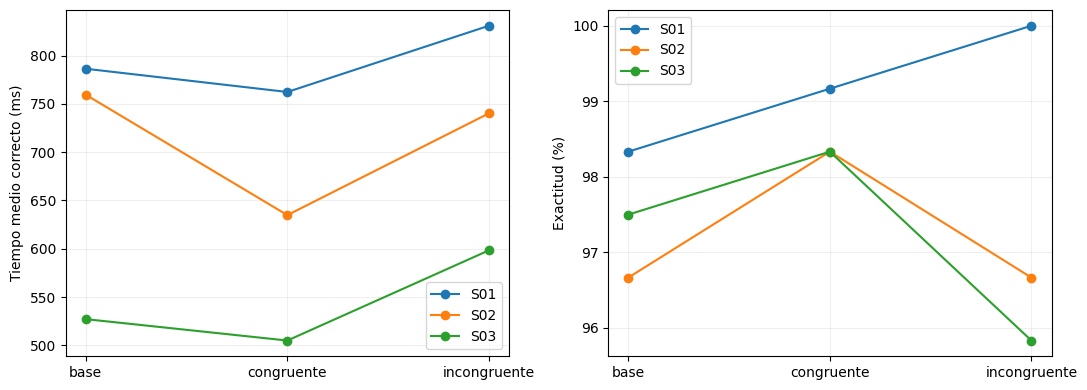

In [ ]:
# La precisión usa todos los ensayos restantes; los tiempos, solo los correctos.
# Resumimos por participante y condición y dibujamos sus trayectorias.
rt=df[df.correct.eq(1)].copy()
summary=df.groupby(['subject','condition']).agg(n=('correct','size'),accuracy=('correct','mean'),errors=('correct',lambda x:int((1-x).sum())))
times=rt.groupby(['subject','condition']).rt_ms.agg(mean_ms='mean',median_ms='median',sd_ms='std',n_correct='size')
summary=summary.join(times).reset_index()
display(summary)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for subject,g in summary.groupby('subject'):
    g=g.set_index('condition').reindex(CONDITIONS)
    axes[0].plot(CONDITIONS,g.mean_ms,marker='o',label=subject)
    axes[1].plot(CONDITIONS,g.accuracy*100,marker='o',label=subject)
axes[0].set_ylabel('Tiempo medio correcto (ms)');axes[1].set_ylabel('Exactitud (%)')
for ax in axes: ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'comparacion.png',dpi=160);plt.show()


## 3. t de Student pareada y sensibilidad exacta
Con 3 sujetos su p bilateral mínimo es 0,25: no esperar significación. La sensibilidad de mediana y sin primer ensayo es descriptiva; no escoger el análisis según su p.

In [ ]:
# Comparamos medias por participante, conservando el emparejamiento.
# Calculamos IC, tamaño del efecto, permutación de signos y ajuste Holm.
# Las medianas y la exclusión del primer ensayo de cada bloque son sensibilidades.
wide=rt.groupby(['subject','condition']).rt_ms.mean().unstack().reindex(columns=CONDITIONS)
rows=[]
for a,b in itertools.combinations(CONDITIONS,2):
    paired=wide[[a,b]].dropna();delta=(paired[b]-paired[a]).to_numpy();n=len(delta)
    assert n>=2
    t,p=stats.ttest_rel(paired[b],paired[a]);se=stats.sem(delta)
    ci=stats.t.interval(.95,n-1,loc=delta.mean(),scale=se) if se>0 else (delta.mean(),delta.mean())
    signs=np.array(list(itertools.product([-1,1],repeat=n)))
    p_exact=np.mean(np.abs((signs*delta).mean(axis=1))>=abs(delta.mean())-1e-10)
    rows.append(dict(comparison=f'{b} - {a}',n=n,difference_ms=delta.mean(),ci_low=ci[0],ci_high=ci[1],t=t,df=n-1,p=p,dz=delta.mean()/delta.std(ddof=1) if delta.std(ddof=1)>0 else np.nan,p_signflip=p_exact))
t_results=pd.DataFrame(rows);t_results['p_holm']=multipletests(t_results.p,method='holm')[1]
display(t_results)
med=rt.groupby(['subject','condition']).rt_ms.median().unstack()
no_first=rt[rt.trial.gt(1)].groupby(['subject','condition']).rt_ms.mean().unstack()
for label,w in [('medianas',med),('sin primer ensayo',no_first)]:
    print(label);display(pd.DataFrame({f'{b} - {a}':w[b]-w[a] for a,b in itertools.combinations(CONDITIONS,2)}))


,comparison,n,difference_ms,ci_low,ci_high,t,df,p,dz,p_signflip,p_holm
0,congruente - base,3,-56.958961,-202.627144,88.709223,-1.682417,2,0.234516,-0.971344,0.25,0.469031
1,incongruente - base,3,32.184812,-83.367608,147.737232,1.198418,2,0.353500,0.691907,0.50,0.469031
2,incongruente - congruente,3,89.143773,42.541253,135.746293,8.230342,2,0.014444,4.751790,0.25,0.043331


medianas


,congruente - base,incongruente - base,incongruente - congruente
subject,,,
S01,-22.5,37.5,60.0
S02,-51.5,-7.5,44.0
S03,-28.5,16.0,44.5


sin primer ensayo


,congruente - base,incongruente - base,incongruente - congruente
subject,,,
S01,-28.369074,37.206924,65.575998
S02,-141.256006,-10.372727,130.883279
S03,-24.861889,77.073973,101.935862


## 4. Exactitud: chi cuadrado exploratorio
Tabla condición × acierto/error. Se muestran frecuencias esperadas. Si alguna es menor que 5, la aproximación asintótica es débil. Incluso con frecuencias suficientes, el chi cuadrado agrupado ignora dependencia intra-sujeto: su p NO es evidencia confirmatoria. Fisher tampoco resuelve esa dependencia. Se añaden diferencias de exactitud por sujeto, sin tratar ensayos como pares naturales (los estímulos cambian).

In [ ]:
# Construimos la tabla de aciertos/errores y el chi cuadrado exploratorio.
# Mostramos también diferencias de precisión por participante.
table=pd.crosstab(df.condition,df.correct).reindex(index=CONDITIONS,columns=[0,1],fill_value=0)
display(table.rename(columns={0:'error',1:'acierto'}))
if (table.sum(axis=0)>0).all():
    chi,p,dof,expected=stats.chi2_contingency(table,correction=False)
    chi_results=pd.DataFrame([dict(chi2=chi,p_exploratory=p,df=dof,min_expected=expected.min(),independence_assumption_met=False)])
    display(chi_results);display(pd.DataFrame(expected,index=CONDITIONS,columns=['error','acierto']))
else:
    chi_results=pd.DataFrame();print('Chi cuadrado no calculable: columna sin observaciones.')
accuracy=df.groupby(['subject','condition']).correct.mean().unstack()
display(pd.DataFrame({f'{b} - {a} (puntos porcentuales)':100*(accuracy[b]-accuracy[a]) for a,b in itertools.combinations(CONDITIONS,2)}))


correct,error,acierto
condition,,
base,9,351
congruente,5,355
incongruente,9,351


,chi2,p_exploratory,df,min_expected,independence_assumption_met
0,1.421579,0.491256,2,7.666667,False


,error,acierto
base,7.666667,352.333333
congruente,7.666667,352.333333
incongruente,7.666667,352.333333


,congruente - base (puntos porcentuales),incongruente - base (puntos porcentuales),incongruente - congruente (puntos porcentuales)
subject,,,
S01,0.833333,1.666667,0.833333
S02,1.666667,0.000000,-1.666667
S03,0.833333,-1.666667,-2.500000


## 5. Regresión lineal exploratoria
Con tres condiciones, usar dos indicadores, con base como referencia: Y = α + βC·I(congruente) + βI·I(incongruente) + efectos de sujeto + controles + ε. La estadística del coeficiente es **t = β estimado / SE(β estimado)**; no se vuelve a dividir por √n. β se interpreta como asociación ajustada; no necesariamente efecto causal.

Se controlan serie, ensayo dentro del bloque y distancia de cantidades. Si el orden es siempre base→congruente→incongruente, el efecto de condición no puede separarse del lugar del bloque. No incluir orden global junto a todas estas variables: puede ser colineal. Solo tres sujetos impiden confiar en errores agrupados o modelos mixtos para inferencia poblacional; se guardan coeficientes y R², y se omiten p/IC de OLS por ensayo. Se añade regresión con log(tiempo) como sensibilidad a asimetría.

,model,term,coefficient,R2,n_trials
0,rt_ms,Intercept,1001.280727,0.222254,1057
1,rt_ms,"C(condition, Treatment(reference='base'))[T.co...",-60.308246,0.222254,1057
2,rt_ms,"C(condition, Treatment(reference='base'))[T.in...",39.903178,0.222254,1057
3,rt_ms,C(subject)[T.S02],-83.617668,0.222254,1057
4,rt_ms,C(subject)[T.S03],-247.079987,0.222254,1057
5,rt_ms,C(series)[T.3],62.743152,0.222254,1057
6,rt_ms,C(series)[T.4],30.531553,0.222254,1057
7,rt_ms,C(series)[T.5],-65.099752,0.222254,1057
8,rt_ms,C(series)[T.6],-56.254182,0.222254,1057
9,rt_ms,C(series)[T.7],-33.211012,0.222254,1057


rt_ms rango= 12 columnas= 12
log_rt rango= 12 columnas= 12


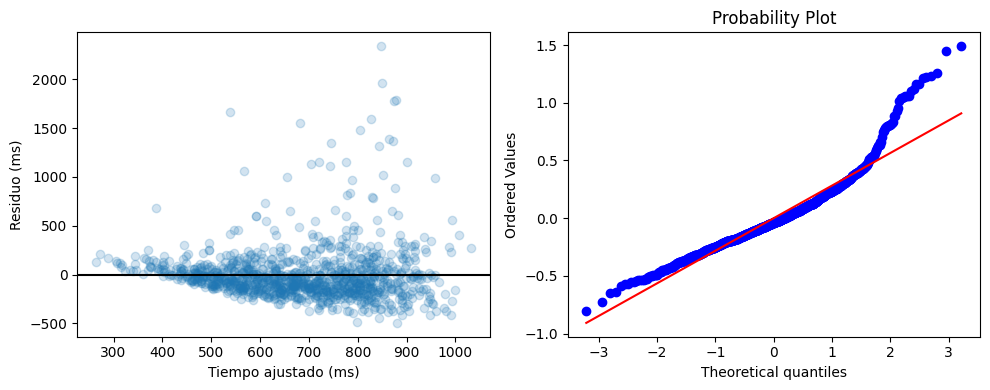

In [ ]:
# Ajustamos tiempo y log(tiempo) por condición, sujeto, serie, ensayo y distancia.
# Exportamos asociaciones descriptivas y examinamos residuos del modelo.
formula="C(condition, Treatment(reference='base')) + C(subject) + C(series) + trial + distance"
models={outcome:smf.ols(outcome+' ~ '+formula,data=rt).fit() for outcome in ['rt_ms','log_rt']}
coefficients=pd.concat([pd.DataFrame({'model':name,'term':model.params.index,'coefficient':model.params.values,'R2':model.rsquared,'n_trials':int(model.nobs)}) for name,model in models.items()],ignore_index=True)
display(coefficients)
for name,m in models.items():
    print(name,'rango=',np.linalg.matrix_rank(m.model.exog),'columnas=',m.model.exog.shape[1])
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].scatter(models['rt_ms'].fittedvalues,models['rt_ms'].resid,alpha=.2);ax[0].axhline(0,color='black');ax[0].set(xlabel='Tiempo ajustado (ms)',ylabel='Residuo (ms)')
stats.probplot(models['log_rt'].resid,dist='norm',plot=ax[1]);plt.tight_layout();plt.show()


Referencias metodológicas: [t pareada](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html), [chi cuadrado](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html), [OLS](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html).

In [ ]:
# Guardamos resultados anónimos calculados después del descarte inicial.
# La exportación individual por ensayo permanece opcional.
summary.to_csv(OUTPUT_DIR/'resumen_anonimo.csv',index=False)
t_results.to_csv(OUTPUT_DIR/'t_pareada.csv',index=False)
chi_results.to_csv(OUTPUT_DIR/'chi_exploratorio.csv',index=False)
coefficients.to_csv(OUTPUT_DIR/'regresion_coeficientes.csv',index=False)
EXPORT_TRIALS=False
if EXPORT_TRIALS: df.to_csv(OUTPUT_DIR/'ensayos_seudonimizados.csv',index=False)
print('Resultados guardados en',OUTPUT_DIR)

Resultados guardados en /content/salidas
